<a href="https://colab.research.google.com/github/tonygruyichich-glitch/ecommerce-customer-retention/blob/main/Copy_of_Data_Analysis_with_Pandas_lecture's_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🎬 IMDb Movie Ratings Analysis

## 🔎 Research Question

**Which movie genres have the highest IMDb ratings?**

In this analysis, we will explore IMDb movie data to identify which genres tend to have the highest average ratings.
---





# Part 1:  Introduction to Pandas & Core Data Structures

---

## 1. What is Pandas?

**Pandas** is a fast, powerful, and flexible open-source library built for data manipulation, cleaning, and analysis in Python. It is built directly on top of **NumPy**, which allows it to execute fast C-level array computations while providing an easy-to-use, human-readable tabular interface.

NumPy (Numerical Python) is the foundational Python library for fast scientific and mathematical computing, providing high-performance multi-dimensional arrays (ndarray) that serve as the performance engine under the hood of Pandas.


---

### 🔑 Key Advantages of Pandas

* **Tabular Data Mastery:** Handles structured data like CSVs, Excel files, and SQL database tables with ease.
* **Smart Data Alignment:** Automatically aligns data based on row labels (indexes) and handles missing values (`NaN`).
* **Expressive Filtering & Querying:** Slice, filter, transform, and aggregate complex datasets in a single line of code.
* **Vectorized Computations:** Performs operations on entire columns simultaneously without using slow Python `for` loops.
* **Ecosystem Integration:** Seamlessly connects with visualization tools (**Matplotlib**, **Seaborn**) and Machine Learning frameworks (**Scikit-Learn**, **PyTorch**).

---

## 2. Core Data Structures: Series vs. DataFrame

Pandas provides two primary data structures:

| Data Structure | Dimensions | Description | Analogous To |
| :--- | :---: | :--- | :--- |
| **Series** | `1D` | A single column of labeled data. | Python List / 1D NumPy Array |
| **DataFrame** | `2D` | A full table with labeled rows and columns. | Excel Spreadsheet / SQL Table |

> 💡 **Concept:** A **DataFrame** can be thought of as a collection of **Series** objects sharing a single, unified row index.

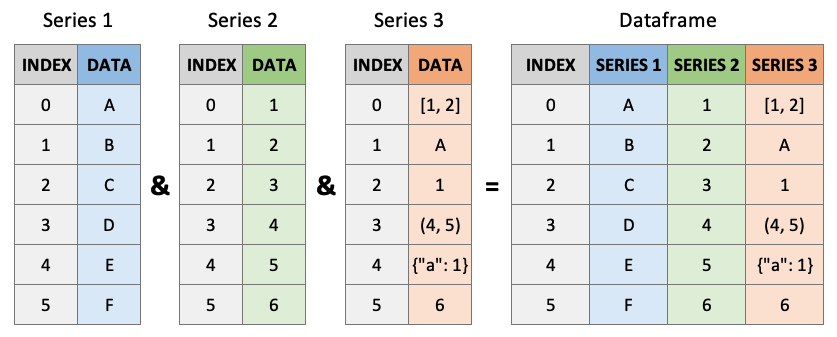

---

## 3. Anatomy of a DataFrame

Understanding how Pandas organizes rows and columns under the hood is critical for indexing and data manipulation.

```text
                       Columns (Header Axis / Axis 1)
                                    │
               ┌────────────────────┼────────────────────┐
               ▼                    ▼                    ▼
           'Name'                 'Age'            'Department'
         ┌───────────────────┬───────────────┬───────────────────┐
     0 ▶ │      Alice        │      28       │    Engineering    │
R    1 ▶ │        Bob        │      34       │     Marketing     │ ◄── Row (Axis 0)
o    2 ▶ │      Charlie      │      22       │       Sales       │
w        └───────────────────┴───────────────┴───────────────────┘
s                                    ▲
                                     │
                             Values / Data Grid
```

### Key Components:

1. **Values Matrix:** The actual 2D grid containing your data. Internally stored as high-performance NumPy arrays.
2. **Index (Row Labels / `Axis 0`):** Labels identifying each row. By default, Pandas assigns integer values ($0, 1, 2, \dots$), but you can set custom labels (strings, dates, UUIDs).
3. **Columns (Column Labels / `Axis 1`):** Names identifying each column. Each column is an independent `Series` object.
4. **Data Types (`dtypes`):** Each column enforces a single explicit data type (e.g., `int64`, `float64`, `object`/string, `bool`, `datetime64`).

---

## 4. Fundamental Concepts in Pandas

### 🔄 The Concept of Axes (`axis=0` vs `axis=1`)

Most Pandas methods accept an `axis` argument:

* `axis=0` (or `axis='index'`): Operations move **vertically** down rows (e.g., computing column sums or averages).
* `axis=1` (or `axis='columns'`): Operations move **horizontally** across columns (e.g., adding two columns together for each row).

> 📌 **Memory Trick:** `axis=0` affects **rows** (collapses vertically), while `axis=1` affects **columns** (evaluates horizontally).

### ⚙️ Immutability vs. In-Place Modifications

* Most Pandas operations **do not change the original object**; they return a *new* modified DataFrame or Series.
* This design prevents accidental data corruption and enables **method chaining**:
  ```python
  df_clean = df.dropna().rename(columns={'old_name': 'new_name'})
  ```

### ❓ Missing Data Handling (`NaN`)

* Missing values are typically represented as `NaN` (*Not a Number*).
* Pandas provides built-in tools (`isna()`, `fillna()`, `dropna()`) to detect, replace, or drop missing entries gracefully.

---

## 5. Official Documentation & API Reference 📚

When working with Pandas, the official documentation is your ultimate guide for exploring every class, method, and parameter.

* 🌐 **Main Documentation Portal:** [pandas.pydata.org/docs](https://pandas.pydata.org/docs/)
* 🔍 **API Reference (All Functions & Methods):** [Pandas API Reference](https://pandas.pydata.org/docs/reference/index.html) — Searchable list of all built-in methods categorized by DataFrames, Series, I/O, Datetime, and more.
* 🚀 **User Guide & Tutorials:** [Pandas User Guide](https://pandas.pydata.org/docs/user_guide/index.html)

> 💡 **Pro-Tip in Google Colab / Jupyter:**
> You don't always need to open a browser to check a function's documentation!
> * Append `?` after any function to view its docstring: `pd.read_csv?`
> * Press `Shift + Tab` inside a function call to open the interactive pop-up documentation.

## 6. Quickstart Notebook Setup

Copy and run this cell in Google Colab to verify your environment setup:

```python
import pandas as pd
import numpy as np

# Print package versions
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version:  {np.__version__}")

# Sample DataFrame Creation
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [28, 34, 22],
    'Department': ['Engineering', 'Marketing', 'Sales']
}

df = pd.DataFrame(data)
df
```

In [ ]:
import pandas as pd
import numpy as np

# Print package versions
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version:  {np.__version__}")

# Sample DataFrame Creation
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [28, 34, 22],
    'Department': ['Engineering', 'Marketing', 'Sales']
}

df = pd.DataFrame(data)
df

Pandas version: {pd.__version__}
NumPy version:  2.1.3


,Name,Age,Department
0,Alice,28,Engineering
1,Bob,34,Marketing
2,Charlie,22,Sales


--------------------------------------------------------------

# Part 2: Data Loading & Saving (I/O)


---

## 1. Overview of Pandas I/O
Pandas provides a vast collection of `read_*` and `to_*` functions to import and export data across various formats:

* **Text Files:** CSV, TSV, TXT
* **Spreadsheets:** Excel (`.xlsx`, `.xls`)
* **Databases:** SQL queries & database connections
* **Web APIs / Web Formats:** JSON, HTML tables
* **Binary Formats:** Parquet, Feather, Pickle

---

### 2. Working with CSV Files (`pd.read_csv` & `to_csv`)

CSV (*Comma-Separated Values*) is the most ubiquitous file format in data science.

### 📥 Importing CSV Data
```python
import pandas as pd

# Basic import
df_csv = pd.read_csv('sample_data.csv')

# Key parameters for advanced loading:
df_custom = pd.read_csv(
    'sample_data.csv',
    sep=',',                  # Delimiter (e.g., ',' or '\t' for tab-separated)
    header=0,                 # Row number to use as column names (0 is default)
    index_col='ID',           # Set a specific column as the DataFrame index
    usecols=['ID', 'Name', 'Price'], # Load only a subset of columns (Saves RAM!)
    nrows=100,                # Read only the first N rows (great for quick testing)
    encoding='utf-8'          # File encoding (use 'latin1' or 'cp1252' for Hebrew/special chars)
)

df_custom.head()
```

### 📤 Exporting to CSV
```python
# Save DataFrame to a CSV file
df_custom.to_csv('cleaned_output.csv', index=False)
# Note: index=False prevents Pandas from writing the integer row numbers into the file!
```

---

## 3. Working with Excel Files (`pd.read_excel` & `to_excel`)

Pandas seamlessly reads multi-sheet Excel files using `openpyxl` as its internal engine.

> 🛠 **Colab Pre-requisite:** `openpyxl` is pre-installed in Google Colab, but locally you may need: `pip install openpyxl`

### 📥 Importing Excel Data
```python
# Read default (first) sheet
df_excel = pd.read_excel('sales_report.xlsx')

# Read a specific sheet by name or index position
df_q1 = pd.read_excel('sales_report.xlsx', sheet_name='Q1_2024')

# Read ALL sheets at once (Returns a dictionary of DataFrames)
all_sheets = pd.read_excel('sales_report.xlsx', sheet_name=None)
print(all_sheets.keys()) # View all sheet names
```

### 📤 Exporting to Excel
```python
# Export a single DataFrame
df_q1.to_excel('q1_report_output.xlsx', sheet_name='Summary', index=False)

# Export multiple DataFrames into different sheets of the SAME workbook
with pd.ExcelWriter('multi_sheet_report.xlsx') as writer:
    df_q1.to_excel(writer, sheet_name='Q1', index=False)
    df_csv.to_excel(writer, sheet_name='RawData', index=False)
```

---

## 4. Importing Built-in Datasets from Seaborn

When practicing or prototyping, you don't need to hunt for external files. The **Seaborn** visualization package comes with popular pre-packaged real-world datasets ready as Pandas DataFrames!

```python
import seaborn as sns

# View available built-in datasets
print(sns.get_dataset_names())

# Load the famous Titanic dataset
df_titanic = sns.load_dataset('titanic')

# Load the Penguins dataset
df_penguins = sns.load_dataset('penguins')

df_penguins.head()
```

> 💡 **Popular Seaborn Datasets for Practice:**
> * `'titanic'` — Classification, missing data handling, categorical analysis.
> * `'penguins'` — Multi-variable statistics & clustering.
> * `'planets'` — Datetime handling & astronomical data.
> * `'tips'` — Regression & financial tipping patterns.

---

## 5. Fetching Live Data from a Web API (JSON)

Modern data pipelines often pull live data directly from web application programming interfaces (APIs).

### Method A: Directly from a JSON Endpoint URL
If the API returns a simple flat JSON list, `pd.read_json()` can fetch and convert it in one line:

```python
# Fetch live public posts data from JSONPlaceholder API
url = 'https://jsonplaceholder.typicode.com/posts'
df_api = pd.read_json(url)

df_api.head()
```

### Method B: Using `requests` + `pd.json_normalize` (For Nested JSONs)
Real-world APIs usually return nested JSON objects. Combining the `requests` module with Pandas' `json_normalize` flattens complex structures into tabular form:

```python
import requests

# Query GitHub API for public repositories mentioning 'pandas'
response = requests.get('https://api.github.com/search/repositories', params={'q': 'pandas'})
data = response.json() # Parse JSON response to a Python dict

# Extract and flatten the 'items' key containing repository information
df_repos = pd.json_normalize(data['items'])

# Inspect extracted top columns
df_repos[['name', 'owner.login', 'stargazers_count', 'html_url']].head()
```

---

## 6. Practical Hands-On Exercise 🏋️‍♂️

Try running this block to test reading directly from a remote GitHub CSV file URL without downloading it first:

```python
# Load world university rankings directly from a remote web URL
remote_url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df_remote = pd.read_csv(remote_url)
print(f"Dataset successfully downloaded with shape: {df_remote.shape}")
df_remote.head(3)
```

---

### 📌 Key Takeaways Summary
1. Always set `index=False` when exporting (`to_csv`, `to_excel`) unless your index is meaningful.
2. Use `usecols` and `nrows` when working with huge CSV files to preserve RAM.
3. Seaborn's `sns.load_dataset()` is the fastest way to get realistic sample data for practice.
4. `pd.json_normalize()` is your secret weapon when parsing complex API responses.



---





---





---



## Part 2

In this section, we learn how to import data into Pandas from various sources (files, Google Drive, libraries, and APIs) and how to export processed DataFrames back to files.

## 1. Mounting Google Drive & Checking Files
When working in Google Colab, you often need to access files stored in your Google Drive.

## 2. Loading Data from Files (CSV & Excel)
Pandas provides fast readers for different file formats.

### Common `read_csv` parameters:
- `usecols`: Load only specific columns to save memory.
- `nrows`: Read only the first N rows (great for quick inspection of large files).
- `index_col`: Set a specific column as the row index.

import seaborn as sns

# Option A: Built-in dataset from Seaborn
df_titanic = sns.load_dataset('titanic')
print("Loaded Titanic dataset:", df_titanic.shape)

# Option B: Load directly from a Web CSV URL
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_web = pd.read_csv(url)
print("Loaded dataset from URL:", df_web.shape)

## 4. Saving & Exporting Data
After cleaning or transforming data, save it back to disk.


# Save DataFrame to CSV (index=False prevents adding an extra unnamed column)
df_titanic.to_csv('cleaned_data.csv', index=False)

# Save DataFrame to Excel
# df_titanic.to_excel('cleaned_data.xlsx', index=False, sheet_name='Cleaned')

print("Data saved successfully!")

In [ ]:
#first we must mounting our drive in order to connect our files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# List files in the current working directory
!ls

# List files in a specific folder (e.g., Google Drive)
!ls "/content/drive/MyDrive/python workshop prep 17.9/imdb_datasets/pandas2209"

drive  sample_data
Data_Analysis_with_Pandas.ipynb  title.basics.csv  title.ratings.csv


In [ ]:
#### importing each file in its own row and its own var - not the smartest way
import pandas as pd

# Replace with the path you copied -- not the smartest way
titles_path = '/content/drive/MyDrive/python workshop prep 17.9/imdb_datasets/title.basics.csv'
ratings_path = '/content/drive/MyDrive/python workshop prep 17.9/imdb_datasets/title.ratings.csv'
titles = pd.read_csv(titles_path)
ratings = pd.read_csv(ratings_path)
ratings.head()



,tconst,averageRating,numVotes
0,tt4261704,7.7,8
1,tt28630878,7.8,50
2,tt0391565,5.3,22
3,tt28499352,8.1,10
4,tt10056952,7.5,21


In [ ]:
titles.head()

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt32654449,tvEpisode,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,1,2023.0,NaN,NaN,Adult
1,tt2235515,movie,Fear Lives Here,Fear Lives Here,0,2012.0,NaN,80.0,"Horror,Sci-Fi,Thriller"
2,tt2391566,tvEpisode,Magistratet,Magistratet,0,2003.0,NaN,NaN,"Action,Comedy,History"
3,tt0253693,movie,Shri Krishna Shishtai,Shri Krishna Shishtai,0,1928.0,NaN,NaN,NaN
4,tt1272622,tvEpisode,"The Ears, Nose and Throat","The Ears, Nose and Throat",0,2008.0,NaN,NaN,Documentary


In [ ]:

import os

folder_path = "/content/drive/MyDrive/python workshop prep 17.9/imdb_datasets/pandas2209"

# Get all file/folder names as a standard Python list
files_list = os.listdir(folder_path)

# Check the list
print(files_list)

# Getting all files using a for loop
dfs = {}

for file_name in files_list:
  if file_name.endswith('.csv'):
    df_name = file_name.replace('.csv', '').replace('.', '_')
    print(df_name)
    full_file_path = folder_path + '/' + file_name
    dfs[df_name] = pd.read_csv(filepath_or_buffer=full_file_path)


['Data_Analysis_with_Pandas.ipynb', 'title.basics.csv', 'title.ratings.csv']
title_basics
title_ratings


In [ ]:

import os

folder_path = "/content/drive/MyDrive/python workshop prep 17.9/imdb_datasets/pandas2209"



# Get all file/folder names as a standard Python list
files_list = os.listdir(folder_path)

# Get all file/folder names as a standard Python list
files_list = os.listdir(folder_path)

# Check the list
print(files_list)

# Getting all files using a for loop
dfs = {}

for file_name in files_list:
  if file_name.endswith('.csv'):
    df_name = file_name.replace('.csv', '').replace('.', '_')
    print(df_name)
    full_file_path = folder_path + '/' + file_name
    dfs[df_name] = pd.read_csv(filepath_or_buffer=full_file_path)

new_col_name = []
for col_name in dfs['title_basics'].columns:
  new_col_name.append(col_name.lower())

dfs['title_basics'].columns = new_col_name
new_col_name = []
for col_name in dfs['title_ratings'].columns:
  new_col_name.append(col_name.lower())

dfs['title_ratings'].columns = new_col_name

dfs['title_ratings'].rename(columns = {'tconst':"titleid"}, inplace=True)
print(dfs['title_basics'].columns)
dfs['title_basics'].rename(columns = {'tconst':"titleid"}, inplace=True)
print(dfs['title_basics'].columns)

['Data_Analysis_with_Pandas.ipynb', 'title.basics.csv', 'title.ratings.csv']
title_basics
title_ratings
Index(['tconst', 'titletype', 'primarytitle', 'originaltitle', 'isadult',
       'startyear', 'endyear', 'runtimeminutes', 'genres'],
      dtype='object')
Index(['titleid', 'titletype', 'primarytitle', 'originaltitle', 'isadult',
       'startyear', 'endyear', 'runtimeminutes', 'genres'],
      dtype='object')


In [ ]:
dfs.keys()

dict_keys(['title_basics', 'title_ratings'])

In [ ]:
dfs.keys()

dict_keys(['title_basics', 'title_ratings'])

In [ ]:
new_col_name = []
for col_name in dfs['title_basics'].columns:
  new_col_name.append(col_name.lower())

dfs['title_basics'].columns = new_col_name

In [ ]:
new_col_name = []
for col_name in dfs['title_basics'].columns:
  new_col_name.append(col_name.lower())

dfs['title_basics'].columns = new_col_name
new_col_name = []
for col_name in dfs['title_ratings'].columns:
  new_col_name.append(col_name.lower())

dfs['title_ratings'].columns = new_col_name

In [ ]:
dfs['title_ratings']

,tconst,averagerating,numvotes
0,tt4261704,7.7,8
1,tt28630878,7.8,50
2,tt0391565,5.3,22
3,tt28499352,8.1,10
4,tt10056952,7.5,21
...,...,...,...
999995,tt1745772,8.2,12
999996,tt37330972,8.1,8
999997,tt0710013,6.5,100
999998,tt2604160,8.2,23


In [ ]:
dfs['title_ratings']

,tconst,averageRating,numVotes
0,tt4261704,7.7,8
1,tt28630878,7.8,50
2,tt0391565,5.3,22
3,tt28499352,8.1,10
4,tt10056952,7.5,21
...,...,...,...
999995,tt1745772,8.2,12
999996,tt37330972,8.1,8
999997,tt0710013,6.5,100
999998,tt2604160,8.2,23


In [ ]:
for dico in dfs.keys():
  print(dico,dfs[dico].columns)

title_basics Index(['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult',
       'startYear', 'endYear', 'runtimeMinutes', 'genres'],
      dtype='object')
title_ratings Index(['tconst', 'averageRating', 'numVotes'], dtype='object')


####some personal adjusments
##### turning all columns to be lower case

In [ ]:
#the python way
for dico in dfs.keys():
  dfs[dico].columns= [name.lower() for name in dfs[dico].columns]

#the pandas str accessor way
for dico in dfs.keys():
  dfs[dico].columns= dfs[dico].columns.str.lower()

In [ ]:
dfs['name_basics']

,nconst,primaryname,birthyear,deathyear,primaryprofession,knownfortitles
0,nm17515028,Untung Kusrinto,NaN,NaN,camera_department,"tt43637127,tt16298806,tt34185010"
1,nm1920829,Javier Conde,1975.0,NaN,"actor,archive_footage","tt0356443,tt0266209,tt1865454,tt0373591"
2,nm2394084,Tony Gacon,NaN,NaN,actor,tt0080019
3,nm11792286,Danielle Hobson,NaN,NaN,producer,tt12281990
4,nm13558313,Shawn Roth,NaN,NaN,actor,tt18278650
...,...,...,...,...,...,...
999995,nm1784534,Jallu Junnilainen,NaN,NaN,actor,tt0249131
999996,nm17129231,Muhammad Nuzul Al Ikhsan,NaN,NaN,camera_department,tt36220182
999997,nm5569603,Brian Bonet,NaN,NaN,camera_department,tt2769276
999998,nm7444150,Anna Maria Mouradian,NaN,NaN,"director,animation_department,writer","tt4843772,tt7495382,tt26902654"


#### replacing cardinal columns to easy names
##### we can see that titleid and tconst represents the same entities so lets give them the same name and the catchy one

In [ ]:
dfs['title_ratings'].head()

,tconst,averagerating,numvotes
0,tt4261704,7.7,8
1,tt28630878,7.8,50
2,tt0391565,5.3,22
3,tt28499352,8.1,10
4,tt10056952,7.5,21


In [ ]:
dfs['title_ratings'].rename(columns = {'tconst':"titleid"}, inplace=True)

In [ ]:
dfs['title_ratings'].rename(columns = {'tconst':"titleid"}, inplace=True)
print(dfs['title_basics'].columns)
dfs['title_basics'].rename(columns = {'tconst':"titleid"}, inplace=True)
print(dfs['title_basics'].columns)

Index(['tconst', 'titletype', 'primarytitle', 'originaltitle', 'isadult',
       'startyear', 'endyear', 'runtimeminutes', 'genres'],
      dtype='object')
Index(['titleid', 'titletype', 'primarytitle', 'originaltitle', 'isadult',
       'startyear', 'endyear', 'runtimeminutes', 'genres'],
      dtype='object')


In [ ]:
##replacing multiple names at once. for each df
for dico in dfs.keys():
  dfs[dico].rename(columns={'tconst': 'titleid' },inplace=True)

In [ ]:
for df_name in dfs.keys():
  print(df_name)

title_basics
title_ratings


# Part 3: Exploratory Data Analysis (EDA) — Quick Workflow

1. **Inspect Dimensions & Samples** (`df.shape`, `df.head()`, `df.tail()`, `df.sample()`)
2. **Inspect Metadata & Schema** (`df.info()`, `df.dtypes`, `df.columns`, `df.index`)
3. **Generate Summary Statistics** (`df.describe()`)
4. **Audit Missing Values** (`df.isna().sum()`)
5. **Analyze Unique Values & Frequencies** (`df['col'].value_counts()`, `df.nunique()`)
6. **Check Correlations & Extremes** (`df.corr()`, `df.nlargest()`, `df.nsmallest()`)

In [ ]:
dfs['title_basics']['isadult']

,isadult
0,1
1,0
2,0
3,0
4,0
...,...
999995,1
999996,0
999997,0
999998,0


In [ ]:
dfs['title_basics']['isadult'].isna().sum()

np.int64(0)

In [ ]:
dfs['title_basics']['isadult'].isna().count()

np.int64(1000000)

In [ ]:
dfs['title_basics']['endyear']

,endyear
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
999995,NaN
999996,NaN
999997,NaN
999998,NaN


In [ ]:
dfs['title_basics']['titleid'].value_counts().sort_values()

,count
titleid,
tt32654449,1
tt2235515,1
tt2391566,1
tt0253693,1
tt1272622,1
...,...
tt17592474,1
tt30217547,1
tt30575403,1


In [ ]:
dfs['title_basics']['titleid'].nunique()

1000000

In [ ]:
dfs['title_basics'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   titleid         1000000 non-null  object 
 1   titletype       1000000 non-null  object 
 2   primarytitle    1000000 non-null  object 
 3   originaltitle   1000000 non-null  object 
 4   isadult         1000000 non-null  int64  
 5   startyear       884046 non-null   float64
 6   endyear         12700 non-null    float64
 7   runtimeminutes  375209 non-null   float64
 8   genres          957776 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 68.7+ MB


In [ ]:
dfs['title_basics'].describe()

,isadult,startyear,endyear,runtimeminutes
count,1000000.000000,884046.000000,12700.000000,375209.000000
mean,0.032744,2006.949325,2008.594331,43.336005
std,0.177966,20.192093,16.518739,41.190159
min,0.000000,1881.000000,1937.000000,1.000000
25%,0.000000,2002.000000,2001.000000,21.000000
50%,0.000000,2014.000000,2015.000000,30.000000
75%,0.000000,2020.000000,2021.000000,60.000000
max,1.000000,2032.000000,2028.000000,2854.000000


In [ ]:
dfs['title_ratings'].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).style.format('{:.5f}')
#

,averagerating,numvotes
count,1000000.00000,1000000.00000
mean,6.97346,1053.98971
std,1.39643,18668.18637
min,1.00000,5.00000
1%,2.80000,5.00000
5%,4.40000,6.00000
50%,7.20000,26.00000
95%,9.00000,1389.00000
99%,9.60000,10819.00000
max,10.00000,3238581.00000


#Part 4: Indexing , filtering and fixing crucial columns

In this section, we will learn how to **select, access, and filter data** in a Pandas DataFrame.

### In this section, we will learn how to:

- **Select a single column or multiple columns**
```python
df["Age"]
df[["Name", "Age"]]
```

- **Access rows using `iloc[]` – position-based indexing**
```python
df.iloc[0]
df.iloc[0:5]
```

- **Access rows using `loc[]` – label-based indexing**
```python
df.loc[0]
df.loc[0:5, ["Name", "Age"]]
```

- **Set a column as the DataFrame index**
```python
df = df.set_index("CustomerID")
```

- **Filter rows using a condition**
```python
df[df["Age"] > 30]
```

- **Combine multiple conditions using `&` and `|`**
```python
df[(df["Age"] > 30) & (df["City"] == "London")]
```

- **Filter values using `isin()`**
```python
df[df["City"].isin(["London", "Paris"])]
```

- **Filter values using `between()`**
```python
df[df["Age"].between(20, 30)]
```

- **Filter text using `str.contains()`**
```python
df[df["Name"].str.contains("John")]
```

- **Reset the DataFrame index**
```python
df = df.reset_index(drop=True)
```

Setting an index is useful when a column contains **unique identifiers** or values that you frequently use to identify and access rows.

Resetting the index is especially useful after filtering, when we want the DataFrame to have a clean sequential index starting from `0`.

In [ ]:
musk = dfs['title_basics'].startyear>=2020

In [ ]:

dfs['title_basics'] = dfs['title_basics'][musk]

In [ ]:
dfs['title_basics'].isadult == True

,isadult
0,True
6,False
8,False
15,False
21,False
...,...
999988,False
999991,False
999994,False
999995,True


In [ ]:
test = dfs['title_basics'][(dfs['title_basics'].startyear>2022) & (dfs['title_basics'].isadult == True)]

In [ ]:
test[test.isadult != True]

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres


-----

-----

In [ ]:
## before setting the index on titleid, lets checks if it has any duplicates
print(dfs['title_basics'].titleid.duplicated().sum())
#or using lambda function
print(dfs['title_basics'].titleid.value_counts().apply(lambda x: x > 1).sum())

0
0


In [ ]:
## before setting the index on titleid, lets checks if it has any duplicates
print(dfs['title_basics'].startyear.duplicated().sum())
#or using lambda function
print(dfs['title_basics'].startyear.value_counts().apply(lambda x: x > 1).sum())


999857
140


of course both have duplicate values but why the sums are differents?

value_counts() aggregates the data by unique values, while duplicated() checks each original row against previous rows. Therefore, they count different things.

In [ ]:
print(dfs['title_basics'].startyear.duplicated().head(20))
dfs['title_basics'].startyear.value_counts().head()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14     True
15    False
16     True
17    False
18     True
19     True
Name: startyear, dtype: bool


,count
startyear,
2021.0,41591
2022.0,41116
2023.0,38580
2019.0,37551
2018.0,37454


In [ ]:
dfs['title_basics'].set_index('titleid', inplace=True)
dfs['title_basics'].head(3)

,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres
titleid,,,,,,,,
tt32654449,tvEpisode,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,1,2023.0,NaN,NaN,Adult
tt2235515,movie,Fear Lives Here,Fear Lives Here,0,2012.0,NaN,80.0,"Horror,Sci-Fi,Thriller"
tt2391566,tvEpisode,Magistratet,Magistratet,0,2003.0,NaN,NaN,"Action,Comedy,History"


In [ ]:
dfs['title_basics'].reset_index(inplace=True)
dfs['title_basics'].head(3)

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres
0,tt32654449,tvEpisode,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,Vorgewärmt und abfickbereit!! Bitte nur ohne G...,1,2023.0,NaN,NaN,Adult
1,tt2235515,movie,Fear Lives Here,Fear Lives Here,0,2012.0,NaN,80.0,"Horror,Sci-Fi,Thriller"
2,tt2391566,tvEpisode,Magistratet,Magistratet,0,2003.0,NaN,NaN,"Action,Comedy,History"


## dropping or filling missing values - startyear
#### since startyear is crucial for our analysis, we would like to get rid of its missing values and setting it as a proper int.
also filtering in movies only

In [ ]:
dfs['title_basics'].startyear

,startyear
0,2023.0
1,2012.0
2,2003.0
3,1928.0
4,2008.0
...,...
999995,2021.0
999996,2023.0
999997,1976.0
999998,2003.0


In [ ]:
#how many missing values are there
dfs['title_basics'].startyear.isna().sum()

np.int64(115954)

In [ ]:
#getting rid of the missing vals
dfs['title_basics'] = dfs['title_basics'][dfs['title_basics'].startyear.notna()]

In [ ]:
##converting the columns and saving it as an int
dfs['title_basics']['startyear'] = dfs['title_basics']['startyear'].astype("int")

In [ ]:
musk = dfs['title_basics'].startyear.between(2020,2025)
title_basics_2020 = dfs['title_basics'][musk]

In [ ]:
musk = dfs['title_basics'].startyear.between(2020,2025)
title_basics_2020 = dfs['title_basics'][musk]
musk_movie = title_basics_2020.titletype=='movie'
title_basics_movie_2020 = title_basics_2020[musk_movie]

In [ ]:
title_basics_movie_2020

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres
116,tt38514682,movie,Rei da Noite,Rei da Noite,0,2025.0,NaN,NaN,NaN
555,tt30413112,movie,Hibang,Hibang,0,2023.0,NaN,109.0,Thriller
607,tt6145774,movie,It's Time,It's Time,0,2020.0,NaN,90.0,"Drama,Sport"
950,tt44862819,movie,The Last Living Boy in Buenos Aires,The Last Living Boy in Buenos Aires,0,2025.0,NaN,NaN,Action
1078,tt31546249,movie,The Son of Her Best Friend,The Son of Her Best Friend,0,2024.0,NaN,NaN,Drama
...,...,...,...,...,...,...,...,...,...
999824,tt32886725,movie,Soul Traveler,Soul Traveler,0,2024.0,NaN,97.0,"Fantasy,Horror,Sci-Fi"
999825,tt7050946,movie,American Traitor: The Trial of Axis Sally,American Traitor: The Trial of Axis Sally,0,2021.0,NaN,109.0,"Drama,History,War"
999856,tt17065626,movie,The Cannonball Run Countach,The Cannonball Run Countach: Supercar Legend,0,2022.0,NaN,NaN,Documentary
999933,tt22465898,movie,Love Works: A Story of Healing and Hope,Love Works: A Story of Healing and Hope,0,2022.0,NaN,59.0,NaN


In [ ]:
##filtering out unneeded years and types
dfs['title_basics']=dfs['title_basics'][(dfs['title_basics'].startyear.between(2020, 2025))
  & (dfs['title_basics'].titletype== 'movie')]
dfs['title_basics'].startyear.value_counts().sort_index()

,count
startyear,
2020,1340
2021,1477
2022,1629
2023,1706
2024,1687
2025,1636


#### Filling Missing Genres

We  have some missing values in the `genres` column. Instead of dropping these rows, we will try to infer the missing genre from similar movies.

To make the runtime easier to use for grouping, we previously created the `runtime_group` column, which divides movies into 10-minute runtime ranges.

We will now group the movies by:

- `startyear`
- `runtime_group`

For each group, we will find the **most common genre** and use it to fill the missing values.

```python
dfs['title_basics']["genres_filled"] = (
    dfs['title_basics']
    .groupby(["startyear", "runtime_group"])["genres"]
    .transform(
        lambda x: x.fillna(
            x.mode().iloc[0] if not x.mode().empty else pd.NA
        )
    )
)
```

The existing genre values are not changed. The most common genre is used **only when the original value is missing**.

If no genre can be found for a specific `startyear + runtime_group` combination, the value remains `NaN` rather than being replaced with an arbitrary value.

This approach allows us to preserve more of the original data while making the missing values more useful for our analysis.

In [ ]:
title_basics_movie_2020
#creating runtime_group

bins = [-float("inf"), 80, 90, 100, 110, 120, 130, float("inf")]
labels = ["<80", "80-89", "90-99", "100-109", "110-119", "120-129", "130+"]

title_basics_movie_2020['runtime_group'] = pd.cut(
    title_basics_movie_2020['runtimeminutes'],
    bins=bins,
    labels=labels,
    right=False
)

/tmp/ipykernel_447/3899992576.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  title_basics_movie_2020['runtime_group'] = pd.cut(


In [ ]:
title_basics_movie_2020

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres,runtime_group
116,tt38514682,movie,Rei da Noite,Rei da Noite,0,2025.0,NaN,NaN,NaN,NaN
555,tt30413112,movie,Hibang,Hibang,0,2023.0,NaN,109.0,Thriller,100-109
607,tt6145774,movie,It's Time,It's Time,0,2020.0,NaN,90.0,"Drama,Sport",90-99
950,tt44862819,movie,The Last Living Boy in Buenos Aires,The Last Living Boy in Buenos Aires,0,2025.0,NaN,NaN,Action,NaN
1078,tt31546249,movie,The Son of Her Best Friend,The Son of Her Best Friend,0,2024.0,NaN,NaN,Drama,NaN
...,...,...,...,...,...,...,...,...,...,...
999824,tt32886725,movie,Soul Traveler,Soul Traveler,0,2024.0,NaN,97.0,"Fantasy,Horror,Sci-Fi",90-99
999825,tt7050946,movie,American Traitor: The Trial of Axis Sally,American Traitor: The Trial of Axis Sally,0,2021.0,NaN,109.0,"Drama,History,War",100-109
999856,tt17065626,movie,The Cannonball Run Countach,The Cannonball Run Countach: Supercar Legend,0,2022.0,NaN,NaN,Documentary,NaN
999933,tt22465898,movie,Love Works: A Story of Healing and Hope,Love Works: A Story of Healing and Hope,0,2022.0,NaN,59.0,NaN,<80


In [ ]:
#creating runtime_group

bins = [-float("inf"), 80, 90, 100, 110, 120, 130, float("inf")]
labels = ["<80", "80-89", "90-99", "100-109", "110-119", "120-129", "130+"]

dfs['title_basics']['runtime_group'] = pd.cut(
    dfs['title_basics']['runtimeminutes'],
    bins=bins,
    labels=labels,
    right=False
)

In [ ]:
#creating new genre filled column
title_basics_movie_2020["genres_filled"] = (
    title_basics_movie_2020.groupby(["startyear", "runtime_group"])["genres"]
      .transform(
          lambda x: x.fillna(
              x.mode().iloc[0] if not x.mode().empty else pd.NA
          )
      )
)

/tmp/ipykernel_447/872642520.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  title_basics_movie_2020.groupby(["startyear", "runtime_group"])["genres"]
/tmp/ipykernel_447/872642520.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  title_basics_movie_2020["genres_filled"] = (


In [ ]:
dfs['title_basics']['genres'] = dfs['title_basics']['genres_filled']

#### Genre - fixing the rest of the column.

I have two options:

**Option 1 – Keep only the first genre**

```python
df["main_genre"] = df["genres"].str.split(",").str[0]
```

This is simple, but it assumes that the first genre represents the main genre of the movie.

**Option 2 – Split multiple genres into separate rows**

```python
df["genres"] = df["genres"].str.split(",")
df = df.explode("genres")
```

This preserves all the genre information. A movie with multiple genres will appear once for each genre.

For our analysis, I prefer **Option 2**, because a movie can genuinely belong to multiple genres, and we don't want to discard that information.

**Does this create a bias in our conclusion?**

No. `explode()` does not change the rating of any movie or give it additional weight within a genre. It only allows a movie to be analyzed under every genre it belongs to.

Therefore, the conclusion about **which genres have higher average ratings** is not artificially biased by the transformation. We are preserving the original relationship between each movie and its genres rather than removing part of that information.

> **Important:** When counting movies, we should use `nunique()` on `titleId` to make sure each movie is counted only once within each genre.

In [ ]:
dfs['title_basics'][dfs['title_basics'].genres.notna()]

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres,runtime_group,genres_filled
555,tt30413112,movie,Hibang,Hibang,0,2023,NaN,109.0,Thriller,100-109,Thriller
607,tt6145774,movie,It's Time,It's Time,0,2020,NaN,90.0,"Drama,Sport",90-99,"Drama,Sport"
1174,tt12492840,movie,Le divorce de mes marrants,Le divorce de mes marrants,0,2021,NaN,83.0,"Documentary,Musical",80-89,"Documentary,Musical"
1350,tt23326074,movie,Berlin Cake,Berlin Cake,0,2023,NaN,80.0,Drama,80-89,Drama
1411,tt13408944,movie,A Song for Imogene,A Song for Imogene,0,2023,NaN,103.0,Drama,100-109,Drama
...,...,...,...,...,...,...,...,...,...,...,...
999785,tt16824022,movie,The Last Word,The Last Word,0,2023,NaN,111.0,Comedy,110-119,Comedy
999824,tt32886725,movie,Soul Traveler,Soul Traveler,0,2024,NaN,97.0,"Fantasy,Horror,Sci-Fi",90-99,"Fantasy,Horror,Sci-Fi"
999825,tt7050946,movie,American Traitor: The Trial of Axis Sally,American Traitor: The Trial of Axis Sally,0,2021,NaN,109.0,"Drama,History,War",100-109,"Drama,History,War"
999933,tt22465898,movie,Love Works: A Story of Healing and Hope,Love Works: A Story of Healing and Hope,0,2022,NaN,59.0,Documentary,<80,Documentary


In [ ]:
pd.set_option("display.max_rows", None)

print(dfs['title_basics'].genres.value_counts().head(30))
pd.reset_option("display.max_rows")

genres
Documentary              1936
Drama                    1299
Comedy                    398
Horror                    276
Thriller                  175
Comedy,Drama              162
Action                    135
Romance                   109
Drama,Romance             105
Documentary,Music          88
Drama,Thriller             86
Horror,Thriller            57
Biography,Documentary      55
Comedy,Romance             55
Animation                  54
Music                      53
Comedy,Drama,Romance       51
Sci-Fi                     46
Family                     44
Crime                      41
Comedy,Horror              40
Action,Crime,Drama         39
Crime,Drama                38
Action,Drama               36
Crime,Drama,Thriller       33
Action,Thriller            30
Documentary,History        30
Adventure                  30
Documentary,Drama          28
Drama,Family               28
Name: count, dtype: int64


In [ ]:
dfs['title_basics']['genres_split'] = dfs['title_basics'].genres.str.split(",")


In [ ]:
dfs['title_basics'][['titleid','genres', 'genres_split']].head(10)

,titleid,genres,genres_split
555,tt30413112,Thriller,[Thriller]
607,tt6145774,"Drama,Sport","[Drama, Sport]"
1174,tt12492840,"Documentary,Musical","[Documentary, Musical]"
1350,tt23326074,Drama,[Drama]
1411,tt13408944,Drama,[Drama]
1559,tt16733808,"Comedy,Crime,Fantasy","[Comedy, Crime, Fantasy]"
1840,tt34388357,Comedy,[Comedy]
2062,tt11644714,Drama,[Drama]
2369,tt16566428,"Drama,Thriller","[Drama, Thriller]"
2465,tt35673823,Drama,[Drama]


In [ ]:
#before we saving the new exploded df lets check how the transformation looks like with few titles as examples
dfs['title_basics'][dfs['title_basics'].titleid.isin(['tt16733808','tt12492840','tt23326074'])].explode('genres_split')
#as we can see each title has been multiplied by the number of genera he is assigned too

,titleid,titletype,primarytitle,originaltitle,isadult,startyear,endyear,runtimeminutes,genres,runtime_group,genres_filled,genres_split
1174,tt12492840,movie,Le divorce de mes marrants,Le divorce de mes marrants,0,2021,NaN,83.0,"Documentary,Musical",80-89,"Documentary,Musical",Documentary
1174,tt12492840,movie,Le divorce de mes marrants,Le divorce de mes marrants,0,2021,NaN,83.0,"Documentary,Musical",80-89,"Documentary,Musical",Musical
1350,tt23326074,movie,Berlin Cake,Berlin Cake,0,2023,NaN,80.0,Drama,80-89,Drama,Drama
1559,tt16733808,movie,Complot internacional antilatinoamericano KKKK,Complot internacional antilatinoamericano KKKK,0,2021,NaN,109.0,"Comedy,Crime,Fantasy",100-109,"Comedy,Crime,Fantasy",Comedy
1559,tt16733808,movie,Complot internacional antilatinoamericano KKKK,Complot internacional antilatinoamericano KKKK,0,2021,NaN,109.0,"Comedy,Crime,Fantasy",100-109,"Comedy,Crime,Fantasy",Crime
1559,tt16733808,movie,Complot internacional antilatinoamericano KKKK,Complot internacional antilatinoamericano KKKK,0,2021,NaN,109.0,"Comedy,Crime,Fantasy",100-109,"Comedy,Crime,Fantasy",Fantasy


In [ ]:
dfs['title_basics'] = dfs['title_basics'].explode('genres_split')

# PART 5: Merging DataFrames


In [ ]:
movies = pd.merge(
    dfs["title_basics"],
    dfs["title_ratings"],
    on="titleid",
    how="inner"
)

In [ ]:
final_df = movies[
    ["titleid", "genres_split", "averagerating", "numvotes"]
].copy()

In [ ]:
final_df

,titleid,genres_split,averagerating,numvotes
0,tt12492840,Documentary,5.9,18
1,tt12492840,Musical,5.9,18
2,tt36289534,Drama,8.2,12
3,tt8454312,Drama,5.1,93
4,tt8454312,Thriller,5.1,93
...,...,...,...,...
4407,tt32886725,Horror,4.0,29
4408,tt32886725,Sci-Fi,4.0,29
4409,tt9764362,Comedy,7.1,515334
4410,tt9764362,Horror,7.1,515334


# PART 6: Groupping the  DataFrames


In [ ]:
groupped_df = final_df.groupby("genres_split").agg(
    average_rating=("averagerating", "mean"),
    num_movies=("titleid", "nunique"),
    total_votes=("numvotes", "sum")
).reset_index()

### Data Cleaning After Grouping

After grouping the data, we clean the results to make the comparison between genres more reliable.

First, we remove genres with **fewer than 20 movies**, since their average rating may not be representative.

Then, we filter based on the **average number of votes per movie**, removing genres where ratings are based on relatively few votes.

These steps help us compare genres using more reliable and representative data.

In [ ]:
## we would like to get rid of "noise", dropping categories with less then 20 titles in it
groupped_df = groupped_df[groupped_df["num_movies"] >= 20]

In [ ]:
groupped_df["avg_votes_per_movie"] = (
    groupped_df["total_votes"] / groupped_df["num_movies"]
)

vote_threshold = groupped_df["avg_votes_per_movie"].quantile(0.10)

groupped_df = groupped_df[
    groupped_df["avg_votes_per_movie"] >= vote_threshold
]

/tmp/ipykernel_1104/4200082153.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  groupped_df["avg_votes_per_movie"] = (


# PART 7: Visualizing the Results

Now that we have cleaned, grouped, and aggregated the data, we can visualize the results.

Our goal is to create a clear visualization that helps us answer our research question:

**Which movie genres have the highest IMDb ratings?**

In [ ]:
groupped_df = groupped_df.sort_values(
    "average_rating",
    ascending=False
)

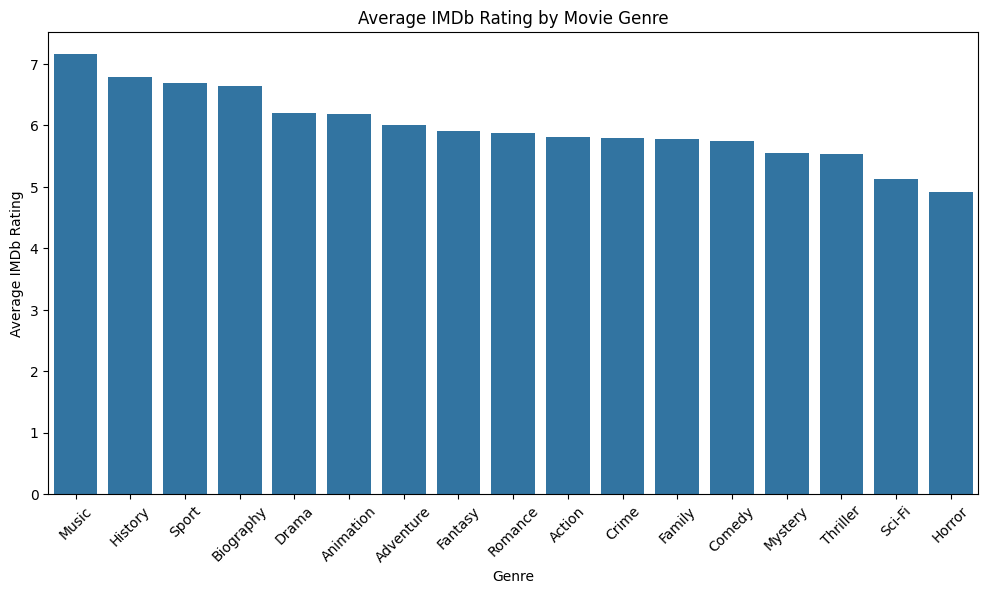

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.barplot(
    data=groupped_df,
    x="genres_split",
    y="average_rating"
)

plt.title("Average IMDb Rating by Movie Genre")
plt.xlabel("Genre")
plt.ylabel("Average IMDb Rating")
plt.xticks(rotation=45)

plt.show()

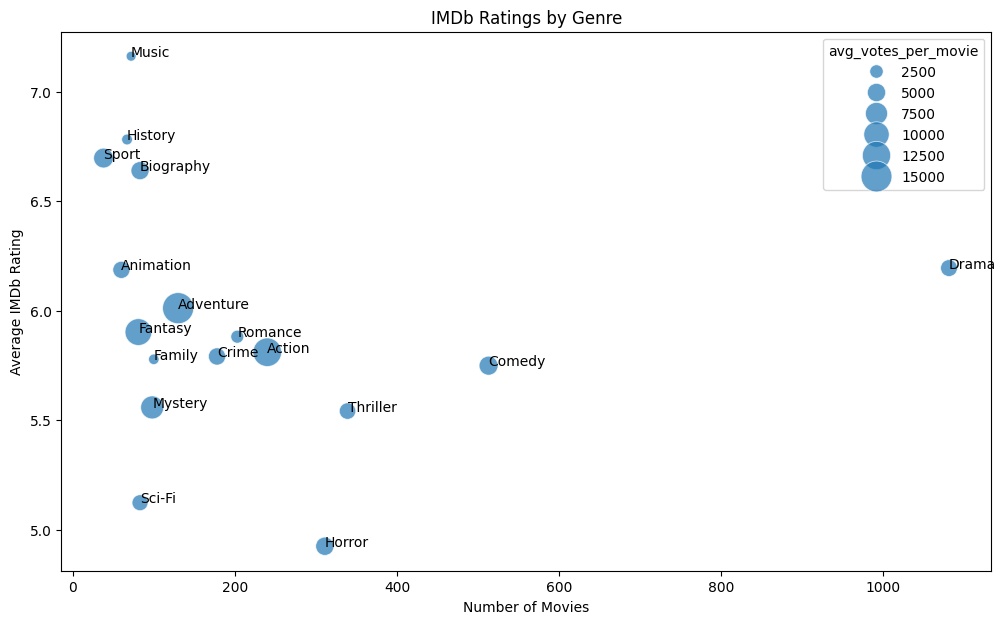

In [ ]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=groupped_df,
    x="num_movies",
    y="average_rating",
    size="avg_votes_per_movie",
    sizes=(50, 500),
    alpha=0.7
)

for _, row in groupped_df.iterrows():
    plt.text(
        row["num_movies"],
        row["average_rating"],
        row["genres_split"]
    )

plt.title("IMDb Ratings by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Average IMDb Rating")

plt.show()

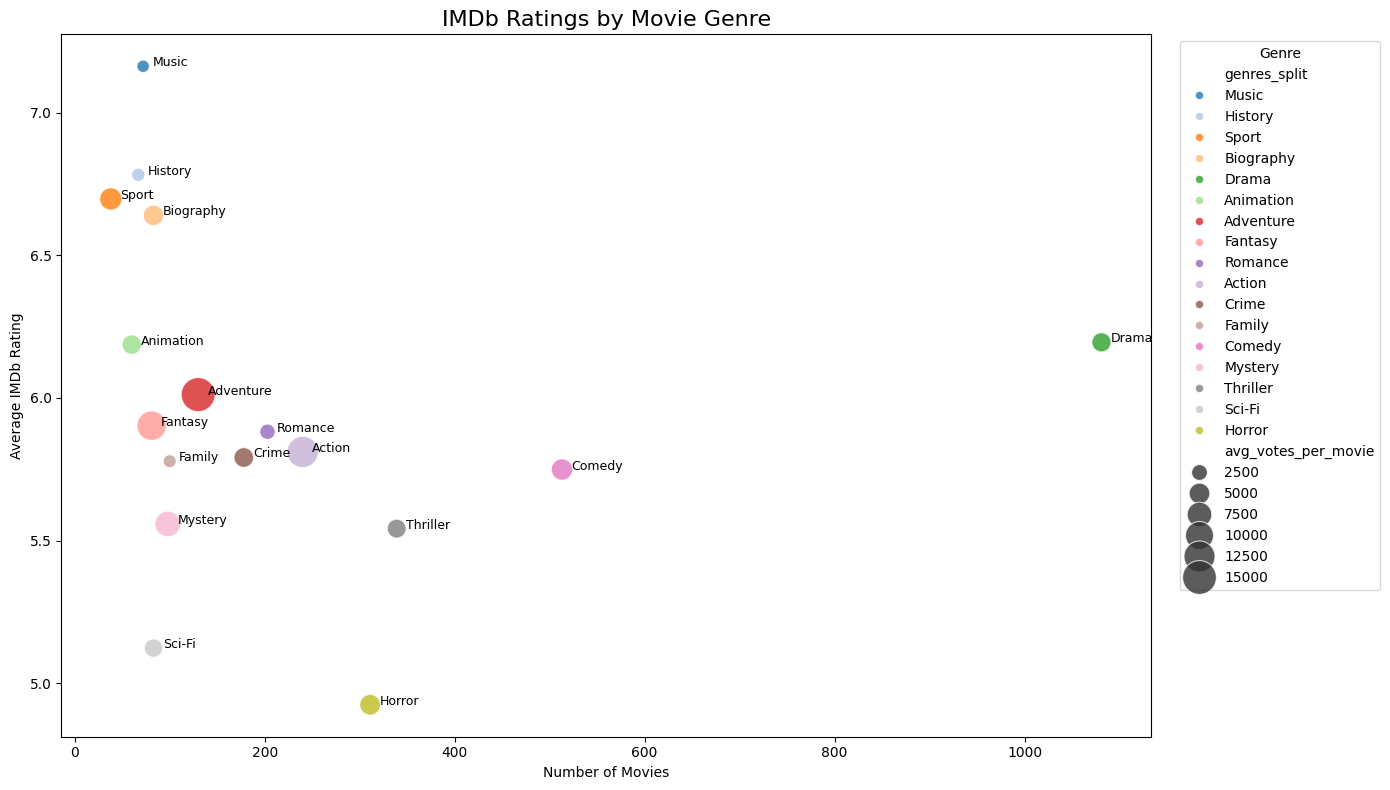

In [ ]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=groupped_df,
    x="num_movies",
    y="average_rating",
    hue="genres_split",
    size="avg_votes_per_movie",
    sizes=(80, 600),
    alpha=0.8,
    palette="tab20"
)

for _, row in groupped_df.iterrows():
    plt.text(
        row["num_movies"] + 10,
        row["average_rating"],
        row["genres_split"],
        fontsize=9
    )

plt.title("IMDb Ratings by Movie Genre", fontsize=16)
plt.xlabel("Number of Movies")
plt.ylabel("Average IMDb Rating")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    title="Genre"
)

plt.tight_layout()
plt.show()

### Understanding a Box Plot

A **Box Plot** helps us understand how a numerical variable is distributed across different groups.

- **Median** – the middle value when all observations are ordered.
- **Box** – contains the middle 50% of the observations, from the 25th to the 75th percentile.
- **Whiskers** – show the typical range of the data outside the box.
- **Outliers** – observations that are unusually far from the rest of the data.
- **Average (Mean)** – the sum of all values divided by the number of observations. It is not directly represented by the box plot unless we explicitly add it.

In our analysis, the Box Plot shows the **distribution of IMDb ratings within each movie genre**, allowing us to see not only the typical rating, but also how much the ratings vary within each genre.

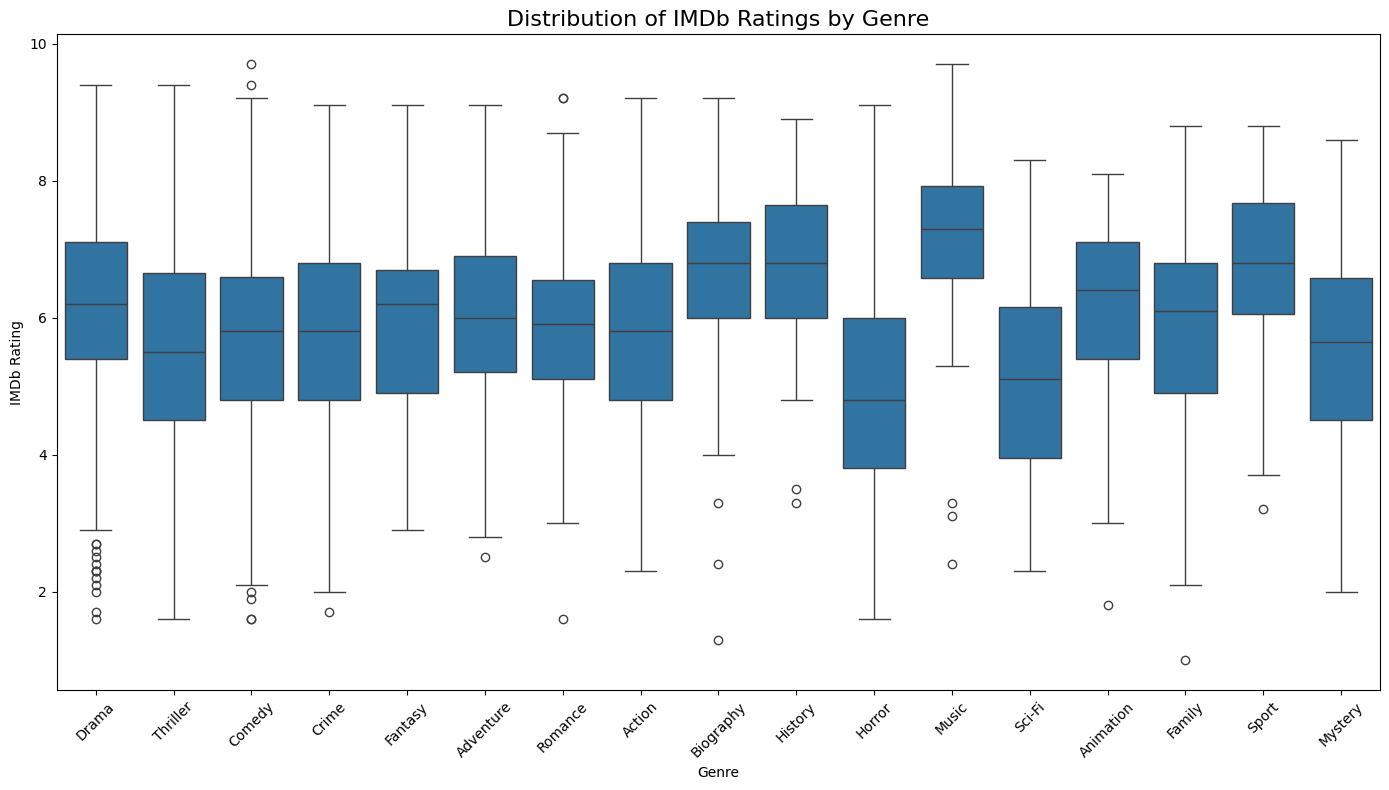

In [ ]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=final_df[
      final_df["genres_split"].isin(groupped_df["genres_split"])],
    x="genres_split",
    y="averagerating"
)

plt.title("Distribution of IMDb Ratings by Genre", fontsize=16)
plt.xlabel("Genre")
plt.ylabel("IMDb Rating")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

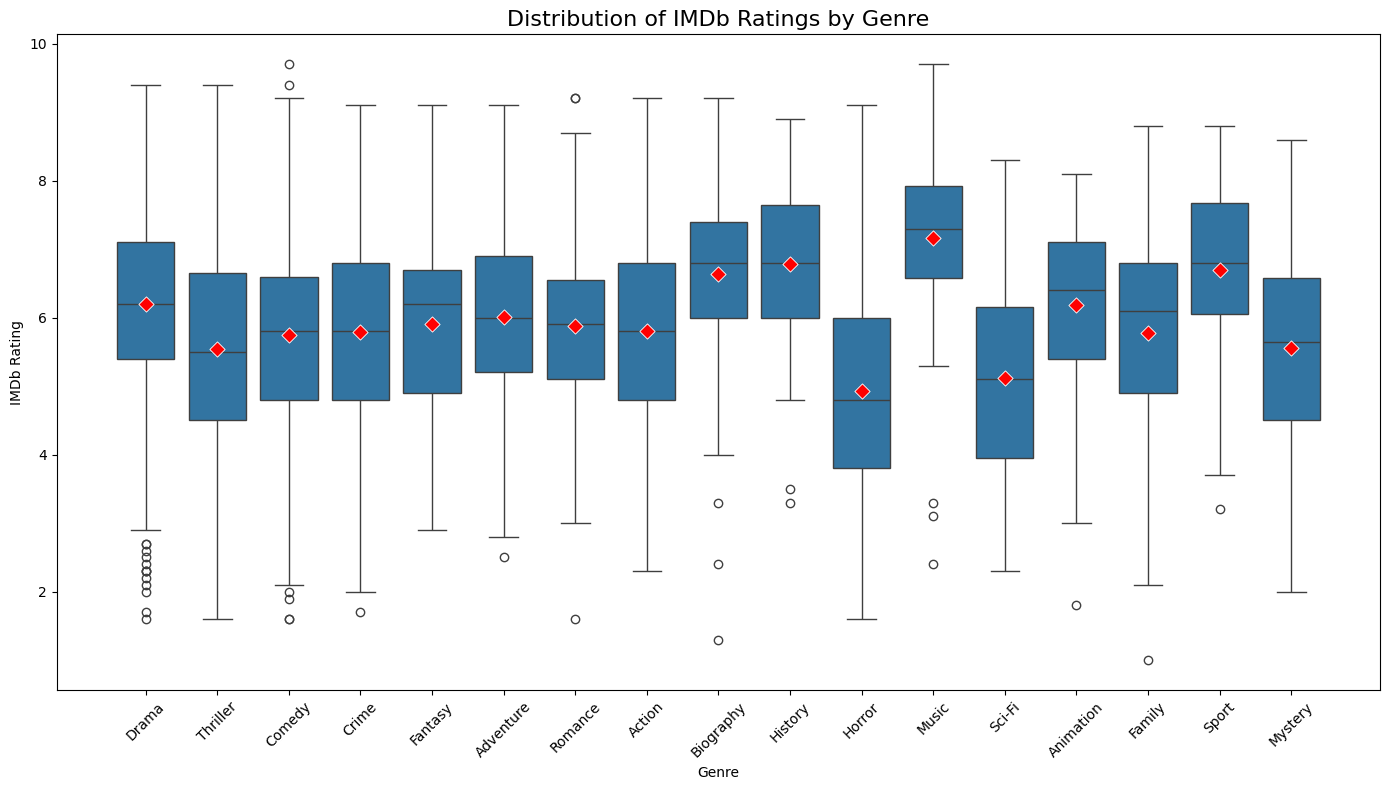

In [ ]:
plt.figure(figsize=(14, 8))

plot_df = final_df[
    final_df["genres_split"].isin(groupped_df["genres_split"])
]

sns.boxplot(
    data=plot_df,
    x="genres_split",
    y="averagerating"
)

# Add average as individual points
avg_ratings = (
    plot_df.groupby("genres_split")["averagerating"]
    .mean()
    .reset_index()
)

sns.scatterplot(
    data=avg_ratings,
    x="genres_split",
    y="averagerating",
    color="red",
    marker="D",
    s=60,
    zorder=10
)

plt.title("Distribution of IMDb Ratings by Genre", fontsize=16)
plt.xlabel("Genre")
plt.ylabel("IMDb Rating")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()